# 04 · A classifier learnt from human writing: what does it make of Qwen's texts?

**The classifier.** It learns ONLY from the 25 real (human) texts of notebook 01, labelled factual or creative.
Machine-written texts are only labelled by it, never learnt from. It is a **nearest neighbour (1-NN) with DTW**:
a curve gets the kind of the single real text whose curve is closest (the same DTW as the clustering of
notebook 02: raw curves, nothing averaged).

**How good it is** is measured on the real texts with **leave-one-out**: each real text is labelled from the
other 24, never from itself; the score is how many of the 25 it gets right.

**What it is then used on** (the clean and burst texts of notebook 03, for the three signals of notebook 03):
1. **Whole texts**: the kind 1-NN gives each clean and each burst text, and which reference cluster (notebook 02)
   its curve is closer to (the cluster's centre text, its medoid).
2. **Pieces of a burst text**: before the burst, the hot part, after it. A piece is too short to compare whole
   with a 200-word text, so it is labelled word by word: at every word, are the last `window` words closer to
   the factual cluster's writing or to the creative cluster's (the distance of notebook 03)? The share of words
   nearer the creative cluster is given for each piece, at windows of 5, 10, 15 and 20 words, and for the same
   words of the clean original.

Runtime: a few minutes, no model run.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("HF_HUB_OFFLINE", "1")
warnings.filterwarnings("ignore")
QWEN7B_DIR = Path.cwd()
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "src/note_books/Qwen7B/qwen_config.py").exists():
        QWEN7B_DIR = folder / "src/note_books/Qwen7B"
        break
sys.path.insert(0, str(QWEN7B_DIR))

import analysis
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from analysis.classify import (cluster_kinds, dtw_to_references, leave_one_out, nearer_centre, nearer_cluster_per_word,
                               nearest_neighbour, share_creative)
from analysis.cluster import cluster
from analysis.evolving import evolving_profile, first_row_from_char, references_by_cluster
from analysis.figures import plot_piece_shares, plot_summary, save_to
from analysis.signals import (SIGNALS, curve_with_rows, curves_of, dataset_names, kinds_of, load_tables,
                              signal_by_key)
from qwen_config import (BURST_DIR, BURST_TOKENS_DIR, BURST_WORDS_DIR, CLASSIFY_FIGURES_DIR, CLASSIFY_TABLES_DIR,
                         EVOLVING_SIGNALS, MODEL_NAME, WINDOWS_TO_TRY)

for folder in [CLASSIFY_FIGURES_DIR, CLASSIFY_TABLES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)

real_names = dataset_names()
real_kinds = list(kinds_of(real_names))
real_words, real_tokens = load_tables(real_names, MODEL_NAME)
bursts = pd.read_csv(BURST_DIR / "bursts.csv")
burst_names = list(bursts["text"])
clean_names = list(bursts["clean original"])
burst_words, burst_tokens = load_tables(burst_names, MODEL_NAME, BURST_WORDS_DIR, BURST_TOKENS_DIR)
clean_words, clean_tokens = load_tables(clean_names, MODEL_NAME, BURST_WORDS_DIR, BURST_TOKENS_DIR)
print(len(real_names), "real texts,", len(clean_names), "clean and", len(burst_names), "burst texts")

25 real texts, 6 clean and 6 burst texts


## 1. How good is the classifier on human writing? (leave-one-out, every signal)

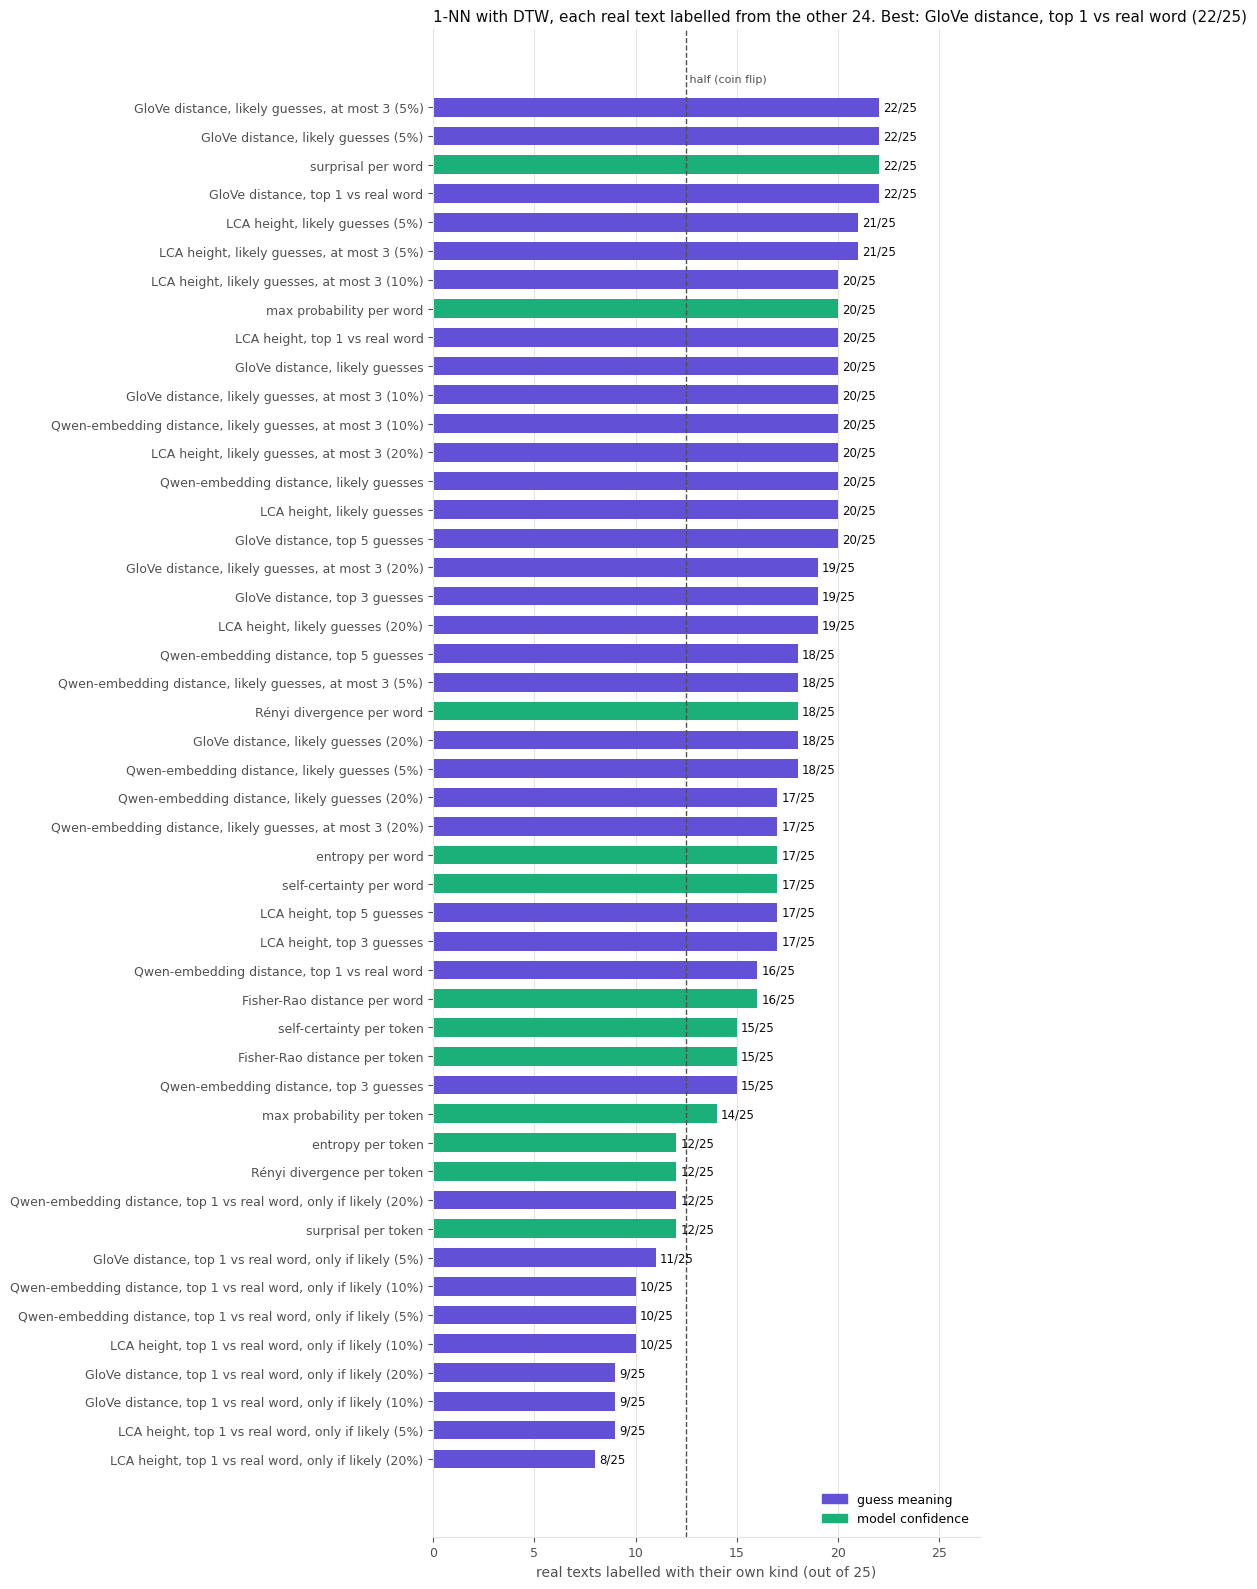

,name,correct,labelled wrong (nearest real text)
36,surprisal per word,22,creative_jokes_for_all_occasions (like factual...
15,"LCA height, likely guesses, at most 3 (10%)",20,factual_gut_candle (like creative_hp7); factua...
6,"GloVe distance, top 5 guesses",20,creative_gut_sherlock (like factual_gut_candle...


In [2]:
loo_rows = []
for signal in SIGNALS:
    curves = curves_of(signal, real_names, real_words, real_tokens)
    _labels, _centres, table = cluster(curves)          # the DTW table between the 25 real texts
    given, nearest = leave_one_out(table, real_kinds)
    wrong = []
    for index in range(len(real_names)):
        if given[index] != real_kinds[index]:
            wrong.append(f"{real_names[index]} (like {real_names[nearest[index]]})")
    right = 0
    for index in range(len(real_names)):
        if given[index] == real_kinds[index]:
            right += 1
    loo_rows.append({"signal": signal.key, "name": signal.name, "family": signal.family, "correct": right,
                     "texts": len(real_names), "labelled wrong (nearest real text)": "; ".join(wrong)})
loo = pd.DataFrame(loo_rows).sort_values("correct", ascending=False)
loo.to_csv(CLASSIFY_TABLES_DIR / "leave_one_out.csv", index=False)

best = loo.iloc[0]
fig = plot_summary(loo, title=f"1-NN with DTW, each real text labelled from the other 24. Best: {best['name']} "
                              f"({best['correct']}/{best['texts']})",
                   xlabel="real texts labelled with their own kind (out of 25)")
save_to(fig, CLASSIFY_FIGURES_DIR, "leave_one_out.png")
plt.show()
display(loo[loo["signal"].isin(EVOLVING_SIGNALS)][["name", "correct", "labelled wrong (nearest real text)"]])

## 2. Qwen's whole texts: which kind does the classifier give them?
For each clean and burst text: the kind 1-NN gives it and the real text it is closest to, and the reference
cluster whose centre text is closer. The `written as` column is what Qwen was asked to write.

In [3]:
generated_names = clean_names + burst_names
generated_words = {**clean_words, **burst_words}
generated_tokens = {**clean_tokens, **burst_tokens}
whole_rows = []
for signal_key in EVOLVING_SIGNALS:
    signal = signal_by_key(signal_key)
    real_curves = curves_of(signal, real_names, real_words, real_tokens)
    labels, centres, _table = cluster(real_curves)
    kind_of_cluster = cluster_kinds(labels, real_kinds)
    generated_curves = curves_of(signal, generated_names, generated_words, generated_tokens)
    to_real = dtw_to_references(generated_curves, real_curves)
    nn_kinds, nearest = nearest_neighbour(to_real, real_kinds)
    centre_kinds = nearer_centre(to_real, centres, kind_of_cluster)
    for index, name in enumerate(generated_names):
        whole_rows.append({"signal": signal.name, "text": name, "written as": name.split("_")[0],
                           "1-NN kind": nn_kinds[index], "nearest real text": real_names[nearest[index]],
                           "nearer cluster centre": centre_kinds[index]})
whole = pd.DataFrame(whole_rows)
whole.to_csv(CLASSIFY_TABLES_DIR / "whole_texts.csv", index=False)

summary_rows = []
for signal_name, rows in whole.groupby("signal", sort=False):
    for part in ["clean", "burst"]:
        part_rows = rows[rows["text"].str.contains(f"_{part}_")]
        summary_rows.append({"signal": signal_name, "texts": f"{part} (6)",
                             "1-NN gives the kind it was written as": int((part_rows["1-NN kind"] ==
                                                                           part_rows["written as"]).sum()),
                             "nearer centre gives it": int((part_rows["nearer cluster centre"] ==
                                                            part_rows["written as"]).sum())})
display(pd.DataFrame(summary_rows))
display(whole)

,signal,texts,1-NN gives the kind it was written as,nearer centre gives it
0,"GloVe distance, top 5 guesses",clean (6),4,2
1,"GloVe distance, top 5 guesses",burst (6),3,2
2,"LCA height, likely guesses, at most 3 (10%)",clean (6),1,1
3,"LCA height, likely guesses, at most 3 (10%)",burst (6),1,1
4,surprisal per word,clean (6),3,2
5,surprisal per word,burst (6),3,2


,signal,text,written as,1-NN kind,nearest real text,nearer cluster centre
0,"GloVe distance, top 5 guesses",factual_clean_paris,factual,factual,factual_gut_candle,creative
1,"GloVe distance, top 5 guesses",factual_clean_apollo,factual,factual,factual_wiki_wordnet,factual
2,"GloVe distance, top 5 guesses",factual_clean_vaccines,factual,factual,factual_wiki_photosynthesis,creative
3,"GloVe distance, top 5 guesses",creative_clean_magic,creative,creative,creative_gut_sherlock,creative
4,"GloVe distance, top 5 guesses",creative_clean_fairy,creative,factual,factual_wiki_photosynthesis,factual
5,"GloVe distance, top 5 guesses",creative_clean_detective,creative,factual,factual_wiki_wordnet,factual
6,"GloVe distance, top 5 guesses",factual_burst_paris,factual,factual,factual_gut_candle,creative
7,"GloVe distance, top 5 guesses",factual_burst_apollo,factual,factual,factual_wiki_photosynthesis,factual
8,"GloVe distance, top 5 guesses",factual_burst_vaccines,factual,factual,factual_wiki_photosynthesis,creative
9,"GloVe distance, top 5 guesses",creative_burst_magic,creative,factual,factual_wiki_photosynthesis,creative


## 3. Pieces of the burst text, at windows of 5, 10, 15 and 20 words
For every burst text, signal and window: the share of words nearer the creative cluster before the burst, in the
hot part (the burst and the `window - 1` words after it, whose windows still reach into it), and after it; and for
the same words in the clean original, and its whole text. 0.5 = as near one cluster as the other on average.

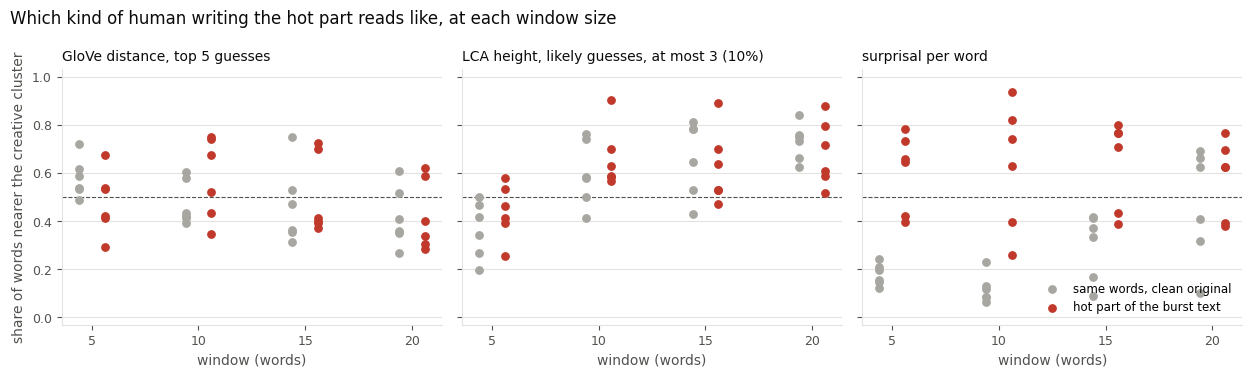

,signal,text,window,before,hot part,after,same words in clean original,whole clean original
0,"GloVe distance, top 5 guesses",factual_burst_paris,5,0.52,0.54,0.48,0.54,0.53
1,"GloVe distance, top 5 guesses",factual_burst_paris,10,0.62,0.67,0.19,0.43,0.54
2,"GloVe distance, top 5 guesses",factual_burst_paris,15,0.47,0.39,0.09,0.47,0.43
3,"GloVe distance, top 5 guesses",factual_burst_paris,20,0.38,0.34,0.00,0.36,0.42
4,"GloVe distance, top 5 guesses",factual_burst_apollo,5,0.49,0.41,0.51,0.49,0.52
...,...,...,...,...,...,...,...,...
67,surprisal per word,creative_burst_fairy,20,0.29,0.77,0.33,0.10,0.35
68,surprisal per word,creative_burst_detective,5,0.32,0.78,0.37,0.15,0.26
69,surprisal per word,creative_burst_detective,10,0.24,0.93,0.19,0.13,0.20
70,surprisal per word,creative_burst_detective,15,0.15,0.76,0.16,0.41,0.29


In [4]:
piece_rows = []
for signal_key in EVOLVING_SIGNALS:
    signal = signal_by_key(signal_key)
    references = references_by_cluster(real_names, real_kinds, curves_of(signal, real_names, real_words, real_tokens))
    for _index, burst in bursts.iterrows():
        table = burst_words[burst["text"]]
        values, rows = curve_with_rows(table, signal.column)
        clean_values, _clean_rows = curve_with_rows(clean_words[burst["clean original"]], signal.column)
        # the burst's measured words on this curve: from the first at or after its start to the last before its end
        first_row = first_row_from_char(table, int(burst["burst start char"]))
        after_row = first_row_from_char(table, int(burst["burst end char"]))
        first = int(np.searchsorted(rows, first_row))
        if after_row is None:
            last = len(rows) - 1
        else:
            last = int(np.searchsorted(rows, after_row)) - 1
        for window in WINDOWS_TO_TRY:
            burst_labels = nearer_cluster_per_word(evolving_profile(values, references, window))
            clean_labels = nearer_cluster_per_word(evolving_profile(clean_values, references, window))
            hot_end = min(last + window, len(burst_labels))      # the last window that still holds a burst word
            piece_rows.append({"signal": signal.name, "text": burst["text"], "window": window,
                               "before": share_creative(burst_labels, 0, first),
                               "hot part": share_creative(burst_labels, first, hot_end),
                               "after": share_creative(burst_labels, hot_end, len(burst_labels)),
                               "same words in clean original": share_creative(clean_labels, first, hot_end),
                               "whole clean original": share_creative(clean_labels, 0, len(clean_labels))})
pieces = pd.DataFrame(piece_rows)
pieces.to_csv(CLASSIFY_TABLES_DIR / "burst_pieces.csv", index=False)

fig = plot_piece_shares(pieces)
save_to(fig, CLASSIFY_FIGURES_DIR, "burst_pieces.png")
plt.show()
display(pieces.round(2))

## 4. What we can gather

**On human writing the classifier works.** Labelling each real text from the other 24, the best signals get 22 of
25 right (GloVe top 1, surprisal per word, GloVe likely 5%). Of the three signals of notebook 03: surprisal 22,
LCA 20, GloVe top 5 20 (its clustering in notebook 02 put 23 in the right group, so 1-NN is no better here).

**On Qwen's whole texts it does not carry over.** Even the clean texts, before any burst, get the kind they were
written as only 4 of 6 times on GloVe, 1 of 6 on LCA and 3 of 6 on surprisal (which calls all of them creative).
Qwen's writing does not read like human writing of the same kind, so a whole-text label from human examples says
little about Qwen's texts, burst or not.

**But the hot part stands out on surprisal, at short windows.** With a 10-word window, every hot part has a
larger share of words nearer the creative cluster (0.26–0.93) than the same words of its clean original
(0.06–0.23) and than its own text before the burst (0.19–0.28). At 5 words the gap is nearly as clean; at 15 and
20 it closes, because longer windows mix the hot part with normal text around it. On GloVe and LCA the hot part is
not separated at any window.

**So:** what shows a burst is not the label itself but the *change* in label against the text's own earlier
words, on surprisal, with windows of about 10 words. The same caveat as notebook 03 holds: surprisal sees hot
writing, true or not.
